In [16]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

In [17]:
base = pd.read_csv("../data/raw/Base.csv")
base.shape

(1000000, 32)

In [2]:
base["fraud_bool"].mean()

0.011029

In [3]:
base.groupby("month")["fraud_bool"].agg(["size", "mean"])

,size,mean
month,,
0,132440,0.011326
1,127620,0.009387
2,136979,0.008746
3,150936,0.009222
4,127691,0.011371
5,119323,0.011825
6,108168,0.013405
7,96843,0.014746


In [4]:
base.to_parquet("../data/processed/base.parquet")

In [5]:
split = pd.cut(base["month"], [-1, 4, 5, 7], labels=["train", "valid", "test"])
base.groupby(split, observed=True)["fraud_bool"].agg(["size", "sum", "mean"])

,size,sum,mean
month,,,
train,675666,6740,0.009975
valid,119323,1411,0.011825
test,205011,2878,0.014038


In [6]:
base.dtypes

fraud_bool                            int64
income                              float64
name_email_similarity               float64
prev_address_months_count             int64
current_address_months_count          int64
customer_age                          int64
days_since_request                  float64
intended_balcon_amount              float64
payment_type                         object
zip_count_4w                          int64
velocity_6h                         float64
velocity_24h                        float64
velocity_4w                         float64
bank_branch_count_8w                  int64
date_of_birth_distinct_emails_4w      int64
employment_status                    object
credit_risk_score                     int64
email_is_free                         int64
housing_status                       object
phone_home_valid                      int64
phone_mobile_valid                    int64
bank_months_count                     int64
has_other_cards                 

In [7]:
(base.select_dtypes("number") < 0).sum()

fraud_bool                               0
income                                   0
name_email_similarity                    0
prev_address_months_count           712920
current_address_months_count          4254
customer_age                             0
days_since_request                       0
intended_balcon_amount              742523
zip_count_4w                             0
velocity_6h                             44
velocity_24h                             0
velocity_4w                              0
bank_branch_count_8w                     0
date_of_birth_distinct_emails_4w         0
credit_risk_score                    14445
email_is_free                            0
phone_home_valid                         0
phone_mobile_valid                       0
bank_months_count                   253635
has_other_cards                          0
proposed_credit_limit                    0
foreign_request                          0
session_length_in_minutes             2015
keep_alive_

In [8]:
base.groupby("customer_age")["fraud_bool"].agg(["size", "mean"])

,size,mean
customer_age,,
10,20987,0.003526
20,245855,0.004901
30,311433,0.008313
40,238712,0.012048
50,140353,0.019985
60,34770,0.033046
70,6517,0.040356
80,1297,0.049345
90,76,0.052632


In [9]:
train = base[base["month"] <= 4]
valid = base[base["month"] == 5]
test = base[base["month"] >= 6]

In [10]:
base[["velocity_6h", "credit_risk_score", "intended_balcon_amount"]].describe()

,velocity_6h,credit_risk_score,intended_balcon_amount
count,1000000.000000,1000000.000000,1000000.000000
mean,5665.296605,130.989595,8.661499
std,3009.380665,69.681812,20.236155
min,-170.603072,-170.000000,-15.530555
25%,3436.365848,83.000000,-1.181488
50%,5319.769349,122.000000,-0.830507
75%,7680.717827,178.000000,4.984176
max,16715.565404,389.000000,112.956928


In [11]:
miss_cols = ["prev_address_months_count", "current_address_months_count",
             "bank_months_count", "session_length_in_minutes",
             "device_distinct_emails_8w"]

rows = []
for c in miss_cols:
    flag = train[c] < 0
    rows.append({
        "col": c,
        "결측비율": flag.mean(),
        "사기율_결측": train.loc[flag, "fraud_bool"].mean(),
        "사기율_그외": train.loc[~flag, "fraud_bool"].mean(),
    })
pd.DataFrame(rows)

,col,결측비율,사기율_결측,사기율_그외
0,prev_address_months_count,0.695472,0.013130,0.002770
1,current_address_months_count,0.004184,0.002830,0.010005
2,bank_months_count,0.254988,0.014847,0.008308
3,session_length_in_minutes,0.001891,0.007825,0.009979
4,device_distinct_emails_8w,0.000408,0.010870,0.009975


In [12]:
cats = ["payment_type", "employment_status", "housing_status", "source", "device_os"]
for c in cats:
    display(train.groupby(c)["fraud_bool"].agg(["size", "mean"]))

,size,mean
payment_type,,
AA,181299,0.005113
AB,235411,0.010152
AC,171511,0.015200
AD,87209,0.009345
AE,236,0.004237


,size,mean
employment_status,,
CA,480770,0.011043
CB,102251,0.006122
CC,27614,0.023068
CD,19680,0.003862
CE,14581,0.002263
CF,30444,0.001807
CG,326,0.012270


,size,mean
housing_status,,
BA,110423,0.034214
BB,171639,0.005634
BC,262914,0.005690
BD,14074,0.008597
BE,115214,0.003220
BF,1201,0.004996
BG,201,0.004975


,size,mean
source,,
INTERNET,670596,0.009942
TELEAPP,5070,0.014398


,size,mean
device_os,,
linux,232252,0.004349
macintosh,35809,0.012036
other,220215,0.005222
windows,182429,0.022453
x11,4961,0.010683


In [13]:
bins = ["email_is_free", "phone_home_valid", "phone_mobile_valid",
        "has_other_cards", "foreign_request", "keep_alive_session"]
pd.concat({c: train.groupby(c)["fraud_bool"].mean() for c in bins}, axis=1)

,email_is_free,phone_home_valid,phone_mobile_valid,has_other_cards,foreign_request,keep_alive_session
0,0.007229,0.012255,0.014385,0.011641,0.009728,0.015472
1,0.012257,0.006362,0.009375,0.003909,0.019128,0.005742


In [14]:
nums = ["name_email_similarity", "velocity_6h", "bank_branch_count_8w",
        "date_of_birth_distinct_emails_4w", "proposed_credit_limit", "income"]
for c in nums:
    q = pd.qcut(train[c], 10, duplicates="drop")
    display(train.groupby(q, observed=True)["fraud_bool"].mean().round(4))

name_email_similarity
(-0.00099857, 0.1]    0.0183
(0.1, 0.179]          0.0178
(0.179, 0.295]        0.0123
(0.295, 0.416]        0.0080
(0.416, 0.506]        0.0060
(0.506, 0.603]        0.0068
(0.603, 0.722]        0.0075
(0.722, 0.817]        0.0089
(0.817, 0.886]        0.0073
(0.886, 1.0]          0.0069
Name: fraud_bool, dtype: float64

velocity_6h
(-130.458, 2372.739]      0.0135
(2372.739, 3697.239]      0.0102
(3697.239, 4628.523]      0.0095
(4628.523, 5480.483]      0.0111
(5480.483, 6274.609]      0.0101
(6274.609, 7126.856]      0.0099
(7126.856, 7943.243]      0.0099
(7943.243, 8812.795]      0.0092
(8812.795, 10245.834]     0.0096
(10245.834, 16715.565]    0.0068
Name: fraud_bool, dtype: float64

bank_branch_count_8w
(-0.001, 1.0]      0.0153
(1.0, 2.0]         0.0117
(2.0, 5.0]         0.0050
(5.0, 10.0]        0.0072
(10.0, 13.0]       0.0087
(13.0, 19.0]       0.0083
(19.0, 43.0]       0.0070
(43.0, 763.0]      0.0064
(763.0, 2381.0]    0.0080
Name: fraud_bool, dtype: float64

date_of_birth_distinct_emails_4w
(-0.001, 4.0]    0.0221
(4.0, 5.0]       0.0110
(5.0, 7.0]       0.0103
(7.0, 8.0]       0.0117
(8.0, 10.0]      0.0090
(10.0, 11.0]     0.0059
(11.0, 13.0]     0.0064
(13.0, 15.0]     0.0055
(15.0, 17.0]     0.0059
(17.0, 39.0]     0.0062
Name: fraud_bool, dtype: float64

proposed_credit_limit
(189.999, 200.0]    0.0065
(200.0, 500.0]      0.0091
(500.0, 1000.0]     0.0093
(1000.0, 1500.0]    0.0195
(1500.0, 2100.0]    0.1213
Name: fraud_bool, dtype: float64

income
(0.099, 0.2]    0.0057
(0.2, 0.3]      0.0063
(0.3, 0.5]      0.0069
(0.5, 0.6]      0.0082
(0.6, 0.7]      0.0086
(0.7, 0.8]      0.0106
(0.8, 0.9]      0.0199
Name: fraud_bool, dtype: float64

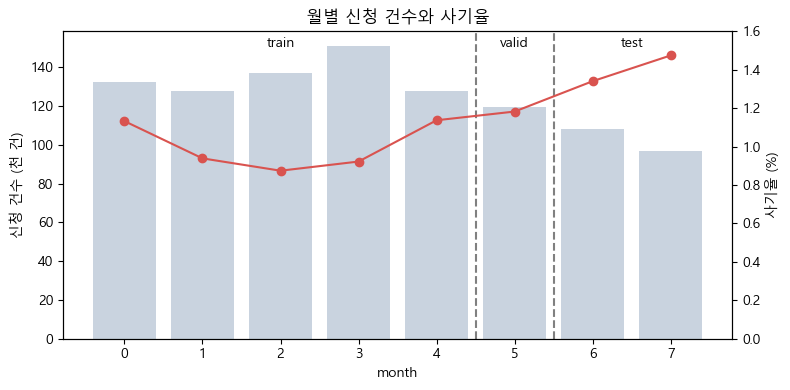

In [21]:
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

monthly = base.groupby("month")["fraud_bool"].agg(["size", "mean"])

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.bar(monthly.index, monthly["size"] / 1000, color="#c9d3df")
ax1.set_xlabel("month")
ax1.set_ylabel("신청 건수 (천 건)")

ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["mean"] * 100, color="#d9534f", marker="o")
ax2.set_ylabel("사기율 (%)")
ax2.set_ylim(0, 1.6)

ax1.axvline(4.5, ls="--", color="gray")
ax1.axvline(5.5, ls="--", color="gray")

ymax = ax1.get_ylim()[1]
ax1.text(2, ymax * 0.95, "train", ha="center")
ax1.text(5, ymax * 0.95, "valid", ha="center")
ax1.text(6.5, ymax * 0.95, "test", ha="center")

plt.title("월별 신청 건수와 사기율")
plt.tight_layout()
plt.savefig("../images/monthly_trend.png", dpi=150)
plt.show()

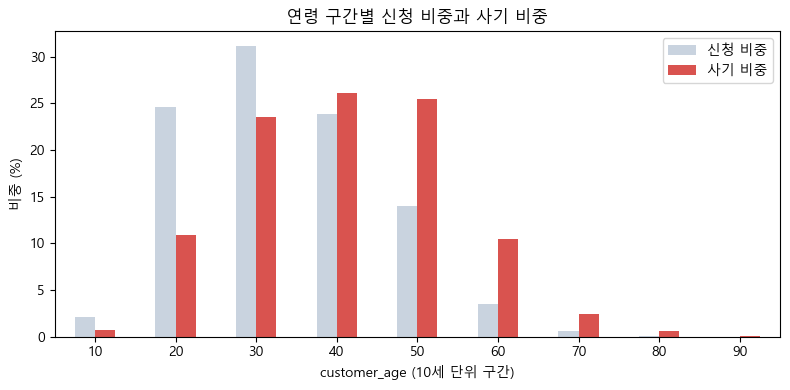

In [18]:
age = base.groupby("customer_age")["fraud_bool"].agg(["size", "sum"])
age["신청 비중"] = age["size"] / age["size"].sum() * 100
age["사기 비중"] = age["sum"] / age["sum"].sum() * 100

age[["신청 비중", "사기 비중"]].plot(
    kind="bar", figsize=(8, 4), color=["#c9d3df", "#d9534f"]
)
plt.xlabel("customer_age (10세 단위 구간)")
plt.ylabel("비중 (%)")
plt.xticks(rotation=0)
plt.title("연령 구간별 신청 비중과 사기 비중")
plt.tight_layout()
plt.show()

<p> 40대부터 사기 비중이 신청 비중을 넘어서는 지점이 보임.<P>
<p> 50대는 신청 14% 대비 사기 25.5%로 차이가 가장 큼.<p>
표에서 계산하면 40세 이상은 신청의 약 42%, 사기의 약 65%이고, 50세 이상은 신청의 18.3%, 사기의 약 38.9%